# Emotional Speech Classification: Initial Data Analysis

**Author**: Tiffany Sun  
**Date**: November 10, 2026

In [1]:
# Import necessary packages, install with !pip or %pip if your system lacks such packages

# %pip install kagglehub
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pylab as plt
import seaborn as sns

#package for accessing multiple files
from glob import glob

For our classification project, we will be using the [RAVDness Emotional Speech Audio Dataset from Kaggle](https://www.kaggle.com/datasets/uwrfkaggler/ravdess-emotional-speech-audio). It contains a total of 1440 audio files from 24 different actors, each with a unique filename of 7 numerical components. A dataframe is constructed for all 1440 files and its stimulus attributes. The dataframe consists of the following variables:

1. Modality: Audio-Video, Video-Only, Audio-Only
2. Vocal Channel: Speech, Song
3. Emotion: Neutral, Calm, Happy, Angry, Sad, Disgust, Fearful, Surprised
4. Emotional Intensity
5. Statement: Expression to be said by an actor
6. Repetition: Number of takes of the statement
7. Actor: A total of 24 actors, 12 males, 12 females

See below the pipeline for creating a dataframe of stimulus features. 

In [2]:
# Extracting audio files from Kaggle
# You'll need to have an API token to access kagglehub
path = kagglehub.dataset_download("uwrfkaggler/ravdess-emotional-speech-audio", output_dir="data/audiofiles")
audiofiles = glob("data/audiofiles/*/*.wav")

# Dataframe
df = pd.DataFrame(columns = ['modality', 'vocal_channel', 'emotion', 'emotional_intensity', 'statement', 'repetition', 'actor', 'audio'] )

def get_features(modality, vocal_channel, emotion, intensity, statement, repetition, actor, audio):
    m = {'01': 'full-AV', 
         '02': 'video_only',
         '03': 'audio-only'}

    v = {'01': 'speech',
         '02': 'song'}

    e = {'01': 'neutral',
         '02': 'calm',
         '03': 'happy',
         '04': 'sad',
         '05': 'angry',
         '06': 'fearful',
         '07': 'disgust',
         '08': 'surprised'}

    i = {
        '01': 'normal',
        '02': 'strong'
    }

    s = {
        '01': 'kids are talking by the door',
        '02': 'dogs are sitting by the door'
    }

    r = {
        '01': '1st repetition',
        '02': '2nd repetition'
    }

    return [m.get(modality), v.get(vocal_channel), e.get(emotion), i.get(intensity), s.get(statement), r.get(repetition), actor, audio]

for audiofile in audiofiles:
    point = audiofile[25:-4].split(sep="-")
    
    df.loc[len(df)]= get_features(point[0], point[1], point[2], point[3], point[4], point[5], point[6], audiofile)

df

,modality,vocal_channel,emotion,emotional_intensity,statement,repetition,actor,audio
0,audio-only,speech,angry,normal,dogs are sitting by the door,1st repetition,16,data/audiofiles/Actor_16/03-01-05-01-02-01-16.wav
1,audio-only,speech,fearful,normal,dogs are sitting by the door,2nd repetition,16,data/audiofiles/Actor_16/03-01-06-01-02-02-16.wav
2,audio-only,speech,fearful,strong,kids are talking by the door,2nd repetition,16,data/audiofiles/Actor_16/03-01-06-02-01-02-16.wav
3,audio-only,speech,angry,strong,kids are talking by the door,1st repetition,16,data/audiofiles/Actor_16/03-01-05-02-01-01-16.wav
4,audio-only,speech,disgust,normal,kids are talking by the door,1st repetition,16,data/audiofiles/Actor_16/03-01-07-01-01-01-16.wav
...,...,...,...,...,...,...,...,...
1435,audio-only,speech,happy,strong,dogs are sitting by the door,2nd repetition,08,data/audiofiles/Actor_08/03-01-03-02-02-02-08.wav
1436,audio-only,speech,happy,normal,kids are talking by the door,2nd repetition,08,data/audiofiles/Actor_08/03-01-03-01-01-02-08.wav
1437,audio-only,speech,calm,strong,kids are talking by the door,1st repetition,08,data/audiofiles/Actor_08/03-01-02-02-01-01-08.wav
1438,audio-only,speech,calm,normal,dogs are sitting by the door,1st repetition,08,data/audiofiles/Actor_08/03-01-02-01-02-01-08.wav


## Univariate Data Analysis
Distributions of attributes are visualized below. Distribution of actors was not visualized, as the dataset description clearly stated that the audio samples were evenly distributed across all actors. 

**Key Takeaways:**
- All 7 non-neutral emotions have equal sample sizes, whereas the neutral baseline has half the sample size of those. 
- The dataset only consists of audio-only, speech files. 
- Sample sizes for the two kinds of statements are identically equal
- Sample sizes for the two kinds of emotional intensities are relatively balanced; the sample size for normal-level intensity is slightly greater than that of the strong-level intensity


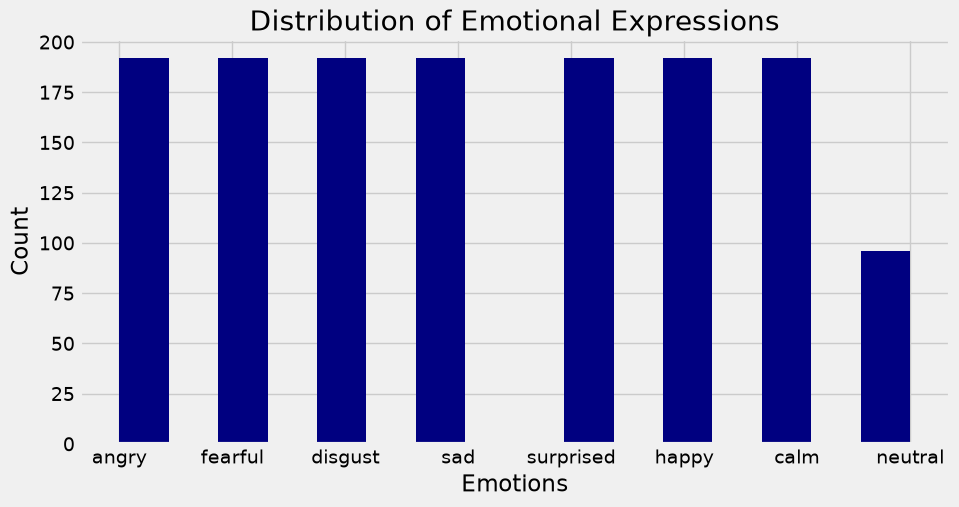

In [5]:
# Distribution of Emotional Expressions
plt.style.use('fivethirtyeight')
plt.figure(figsize=(10, 5))
plt.hist(df['emotion'], bins = 16, color= "navy")
plt.title("Distribution of Emotional Expressions")
plt.xlabel("Emotions")
plt.ylabel("Count")


plt.show()

In [ ]:
# Distribution of Vocal Channels
plt.style.use('fivethirtyeight')
plt.hist(df['vocal_channel'], bins = 1, color= "navy")
plt.title("Distribution of Vocal Channel")
plt.xlabel("Vocal Channel")
plt.ylabel("Count")

plt.show()

In [ ]:
# Distribution of Modality
plt.style.use('fivethirtyeight')
plt.hist(df['modality'], bins = 1, color= "navy")
plt.title("Distribution of Modality")
plt.xlabel("Modality Type")
plt.ylabel("Count")

plt.show()

In [ ]:
# Distribution of Emotional Intensity
plt.style.use('fivethirtyeight')
plt.hist(df['emotional_intensity'], bins = 2, color= "navy")
plt.title("Distribution of Emotional Intensity")
plt.xlabel("Emotional Intensity")
plt.ylabel("Count")

plt.show()

In [ ]:
# Distribution of Statements
plt.style.use('fivethirtyeight')
plt.hist(df['statement'], bins = 2, color= "navy")
plt.title("Distribution of Statements")
plt.xlabel("Statement")
plt.ylabel("Count")

plt.show()

In [ ]:
# Distribution of Repetition
plt.style.use('fivethirtyeight')
plt.hist(df['repetition'], bins = 2, color= "navy")
plt.title("Distributions of Repetition")
plt.xlabel("Repetition Count")
plt.ylabel("Count")

plt.show()

## Next Steps
The next step will be to extract audio features necessary and preprocess our dataset so that it can be ready to train our classification model. Please see 'audio_analysis.ipynb' for the next steps from this initial analysis. Dataframe of audiofiles and its stimulus features are saved to the folder 'data'. 

In [ ]:
# Data 
df.to_csv('data/stimulus_ds', index = True)

## References
1. [RAVDESS Emotional speech audio](https://www.kaggle.com/datasets/uwrfkaggler/ravdess-emotional-speech-audio)
2. [Audio Data Processing in Python](https://www.youtube.com/watch?v=ZqpSb5p1xQo)